## Projeto de Aprendizagem Estatística

In [54]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=["#315C8C", "#24A19C", "#F4A261", "#D95D78", "#7B6DCC"],
)
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#344054",
    "text.color": "#243447",
    "grid.color": "#DCE3EA",
    "grid.alpha": 0.65,
})


In [55]:
df = pd.read_csv("train.csv")
df["stars"] = pd.Categorical(
    df["stars"],
    categories=sorted(df["stars"].dropna().unique()),
    ordered=True,
)
df.head()

,pair_id,user_avg_stars,user_n_ratings,age,share_action,share_comedy,share_drama,movie_avg_stars,movie_n_ratings,genre,release_year,stars
0,P00001,2.99,15,48,0.315,0.501,0.184,3.61,71,drama,2012,3
1,P00002,3.44,35,57,0.180,0.151,0.669,3.15,35,action,2015,2
2,P00003,3.91,46,27,0.701,0.258,0.041,2.72,36,action,1982,4
3,P00004,4.23,23,18,0.700,0.204,0.096,3.26,29,action,2021,5
4,P00005,3.54,29,16,0.621,0.257,0.122,2.83,11,action,2002,4


### Descrição dos Dados

O arquivo `train.csv` contém 4.000 observações. Os exemplos abaixo correspondem à primeira linha do arquivo. Cada linha representa uma combinação entre usuário e filme; a variável resposta é a nota atribuída, de 0 a 5 estrelas. Os dados são fictícios e simulam avaliações de uma plataforma de filmes.

#### Identificação e resposta

| Variável | O que representa | Exemplo |
|---|---|---|
| `pair_id` | Identificador único da combinação usuário–filme. Serve para identificar a linha, não como preditor. | `P00001` |
| `stars` | Nota dada pelo usuário ao filme; variável que queremos explicar ou prever. | `3` estrelas |

#### Características do usuário

| Variável | O que representa | Exemplo |
|---|---|---|
| `user_avg_stars` | Média das notas que o usuário deu a outros filmes. | `2,99` estrelas |
| `user_n_ratings` | Quantidade de avaliações anteriores do usuário. | `15` avaliações |
| `age` | Idade do usuário, em anos. | `48` anos |
| `share_action` | Proporção de filmes de ação no histórico do usuário. | `0,315` = 31,5% |
| `share_comedy` | Proporção de comédias no histórico do usuário. | `0,501` = 50,1% |
| `share_drama` | Proporção de dramas no histórico do usuário. | `0,184` = 18,4% |

As três proporções de gênero somam 1. Por isso, ao usar intercepto em uma regressão, incluímos apenas duas delas para evitar colinearidade perfeita.

#### Características do filme

| Variável | O que representa | Exemplo |
|---|---|---|
| `movie_avg_stars` | Média das notas recebidas anteriormente pelo filme. | `3,61` estrelas |
| `movie_n_ratings` | Quantidade de avaliações anteriores do filme. | `71` avaliações |
| `genre` | Gênero do filme: ação, comédia ou drama. | `drama` |
| `release_year` | Ano de lançamento do filme. | `2012` |

As médias e contagens anteriores são preditores importantes. Para evitar vazamento de informação, elas devem ter sido calculadas sem incluir a nota que o modelo está tentando prever.


In [56]:
num = df.select_dtypes(include="number").columns
cat = df.select_dtypes(include=["object", "category", "string"]).columns
cat = cat[~cat.isin(["pair_id", "stars"]) ]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
user_avg_stars,4000.0,3.337270,0.709814,1.040,2.84000,3.340,3.800,5.000
user_n_ratings,4000.0,58.524250,86.286852,3.000,14.00000,27.000,60.000,1016.000
age,4000.0,36.529250,14.000255,16.000,24.00000,36.000,47.000,79.000
share_action,4000.0,0.389709,0.190547,0.043,0.23700,0.367,0.533,0.867
share_comedy,4000.0,0.295158,0.115637,0.058,0.20775,0.280,0.370,0.722
share_drama,4000.0,0.315133,0.208623,0.031,0.13400,0.238,0.510,0.838
movie_avg_stars,4000.0,3.012265,0.755076,0.310,2.51000,3.010,3.530,5.000
movie_n_ratings,4000.0,55.054750,69.894771,5.000,17.00000,34.000,66.000,1345.000
release_year,4000.0,2004.125500,15.019975,1970.000,1993.00000,2007.500,2017.000,2024.000


### Histogramas das Variáveis Numéricas

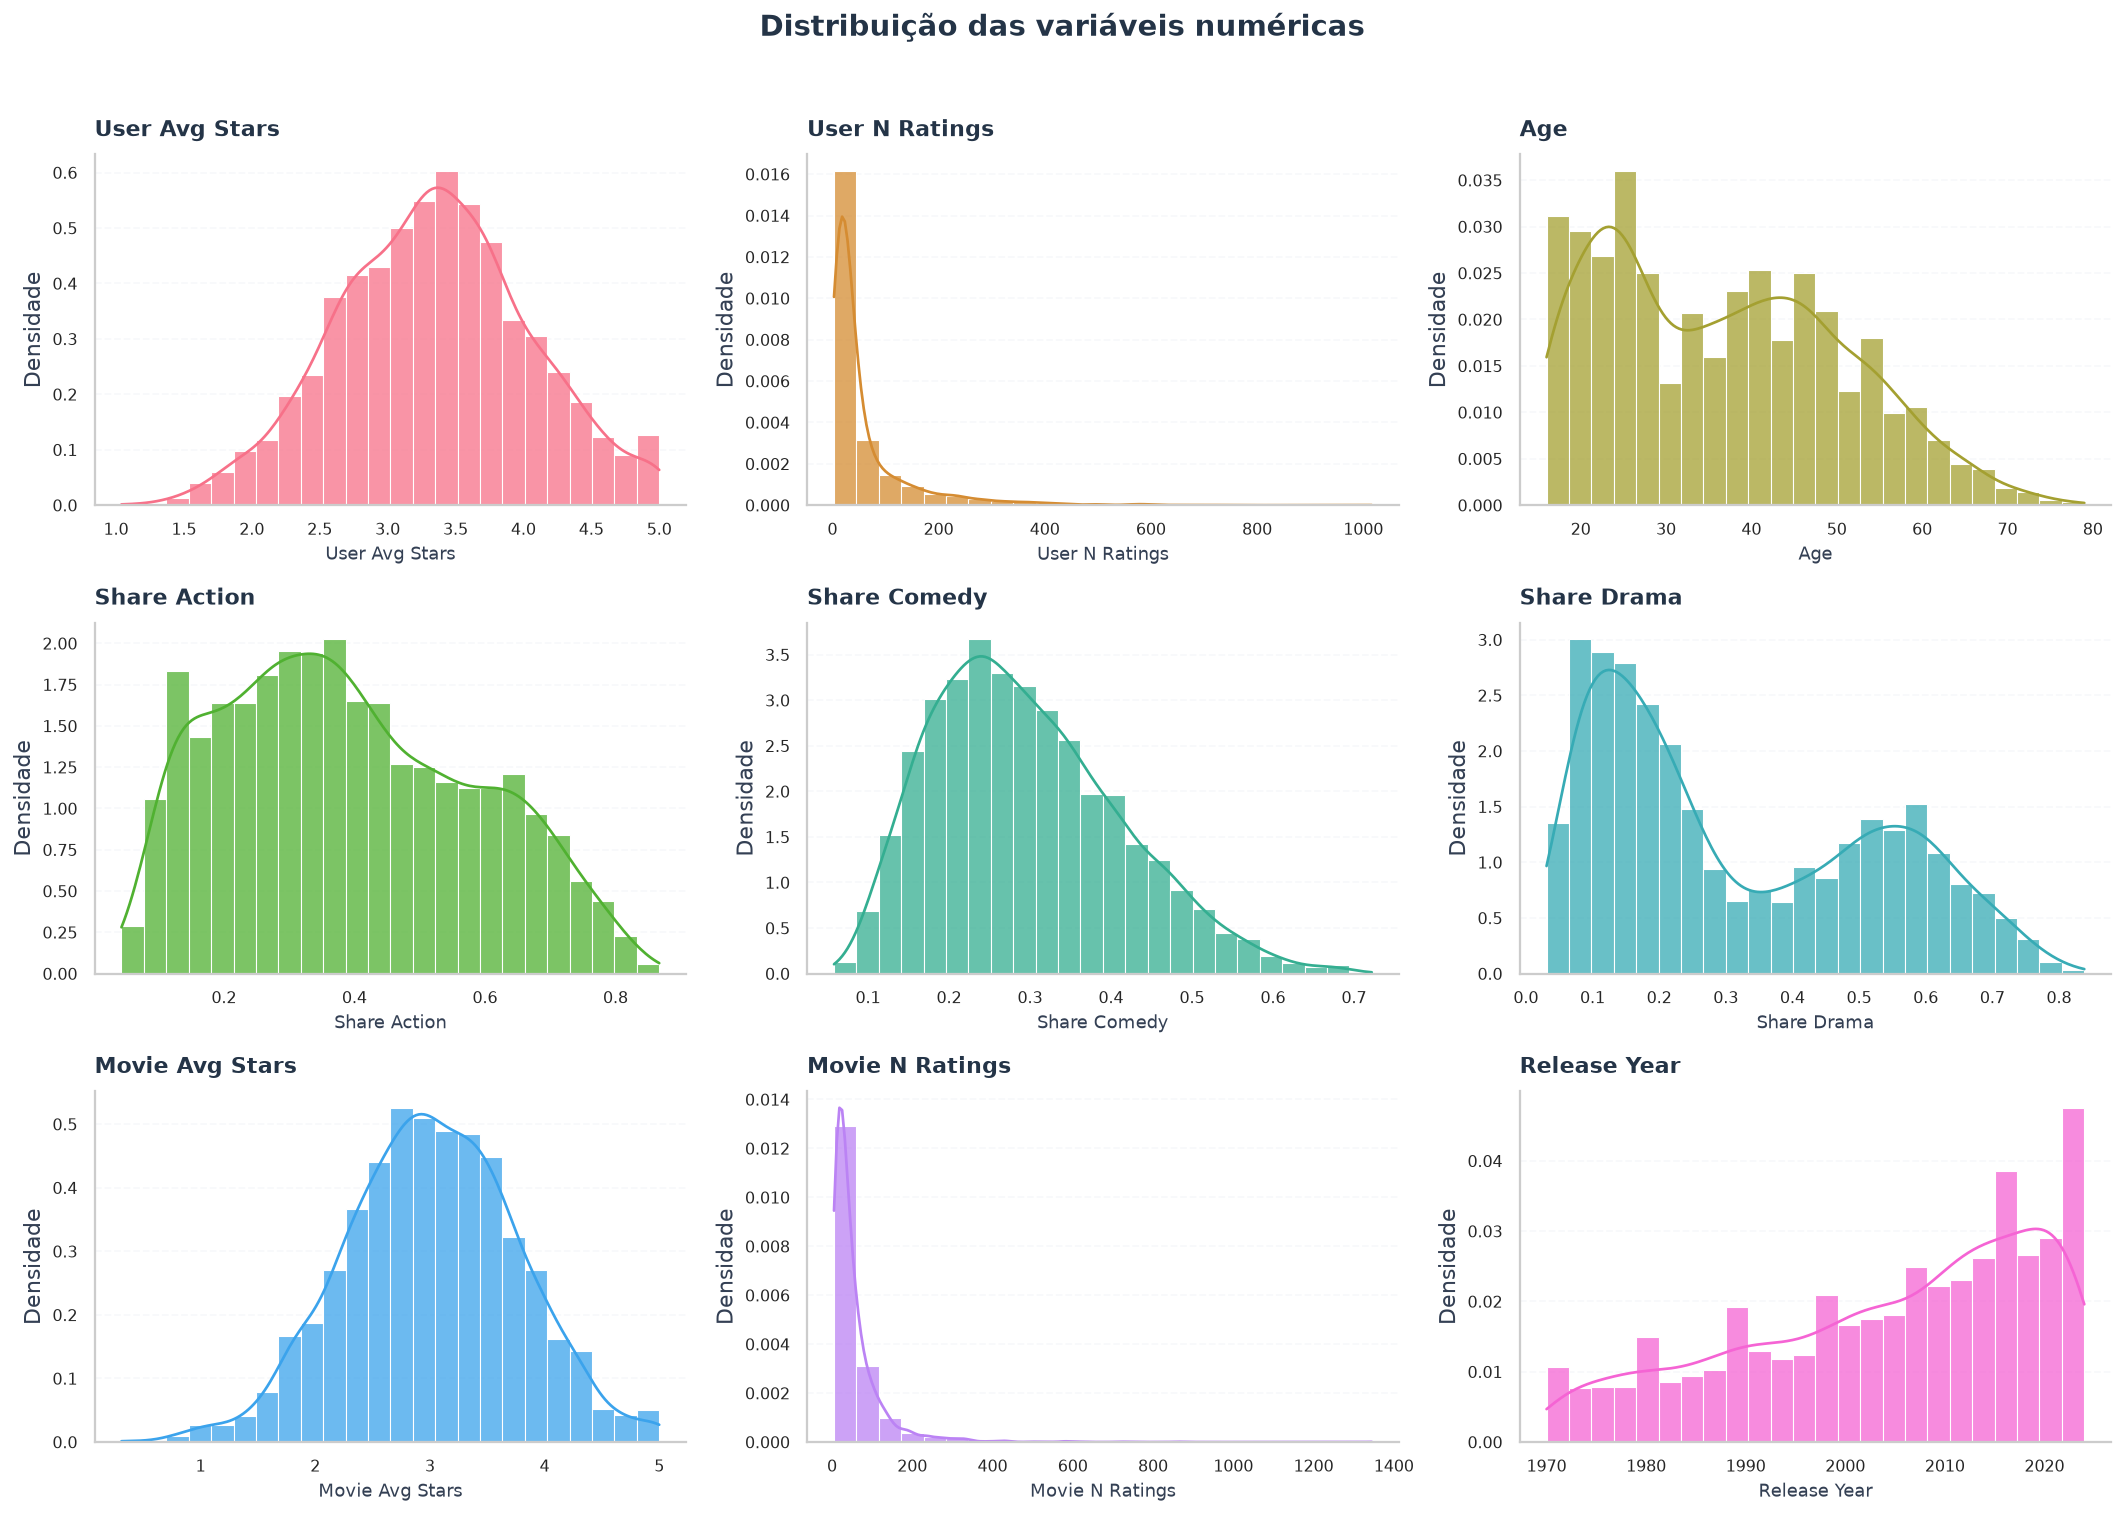

In [57]:
def painel(cols, plot_func, ncols=3, titulo="Distribuição das variáveis numéricas", **kwargs):

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.5 * ncols, 3.8 * nrows),
        squeeze=False
    )

    axes = axes.ravel()
    palette = sns.color_palette("husl", len(cols))

    for i, (ax, col) in enumerate(zip(axes, cols)):

        plot_func(
            data=df,
            x=col,
            ax=ax,
            color=palette[i],
            edgecolor="white",
            linewidth=0.6,
            **kwargs
        )

        nome = col.replace("_", " ").title()

        ax.set_title(nome, loc="left", fontsize=12, fontweight="bold", pad=10)
        ax.set_xlabel(nome, fontsize=10)
        ax.set_ylabel("Densidade" if kwargs.get("stat") == "density" else "Frequência")

        ax.grid(axis="y", alpha=0.2, linestyle="--")
        ax.grid(axis="x", visible=False)

        ax.tick_params(axis="both", labelsize=9)
        sns.despine(ax=ax)

    for ax in axes[len(cols):]:
        ax.set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=16,
        fontweight="bold",
        y=1.02
    )

    fig.tight_layout()
    plt.show()
    
painel(
    num,
    sns.histplot,
    kde=True,
    stat="density",
    bins=24,
    alpha=0.75
)

### Distribuição das Variáveis Categóricas e Ordinais

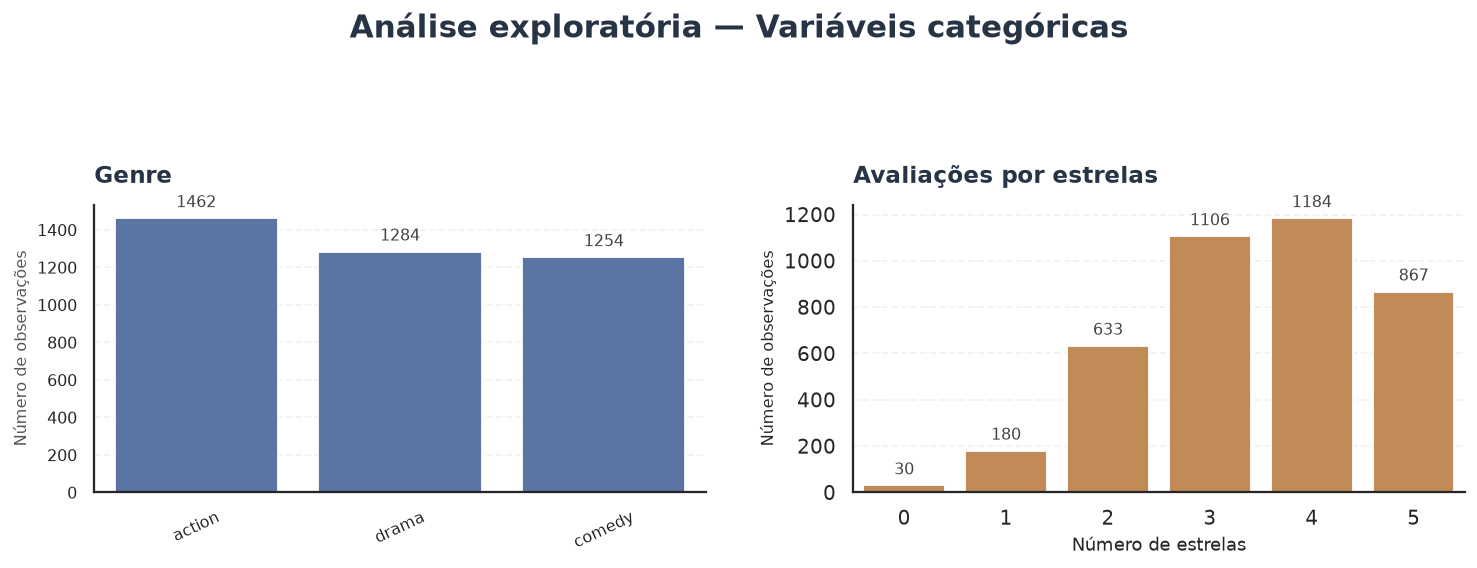

In [58]:
# Configuração visual
sns.set_theme(style="white", context="notebook")

n = len(cat) + 1
ncols = min(n, 3)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 4.5 * nrows),
    squeeze=False
)

axes = axes.flatten()

# Paleta
colors = sns.color_palette("deep", n_colors=n)

# Variáveis categóricas
for i, col in enumerate(cat):

    ax = axes[i]
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        color=colors[i],
        edgecolor="white",
        linewidth=1,
        ax=ax
    )

    # Valores nas barras
    for container in ax.containers:
        ax.bar_label(container, padding=4, fontsize=9, color="#444444")

    ax.set_title(
        col.replace("_", " ").title(),
        loc="left",
        fontsize=13,
        fontweight="bold",
        color="#263445",
        pad=12
    )

    ax.set_xlabel("")
    ax.set_ylabel("Número de observações", fontsize=9, color="#555555")
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)

    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    sns.despine(ax=ax, left=False, bottom=False)


# Avaliações
ax = axes[len(cat)]

sns.countplot(
    data=df,
    x="stars",
    order=sorted(df["stars"].dropna().unique()),
    color="#D28B45",
    edgecolor="white",
    linewidth=1,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fontsize=9, color="#444444")

ax.set_title(
    "Avaliações por estrelas",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="#263445",
    pad=12
)

ax.set_xlabel("Número de estrelas", fontsize=10)
ax.set_ylabel("Número de observações", fontsize=9)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

sns.despine(ax=ax)


# Ocultar espaços vazios
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(
    "Análise exploratória — Variáveis categóricas",
    fontsize=17,
    fontweight="bold",
    color="#263445",
    y=1.02
)

fig.tight_layout(pad=2.5)
plt.show()

### Análise de Correlação das Covariáveis

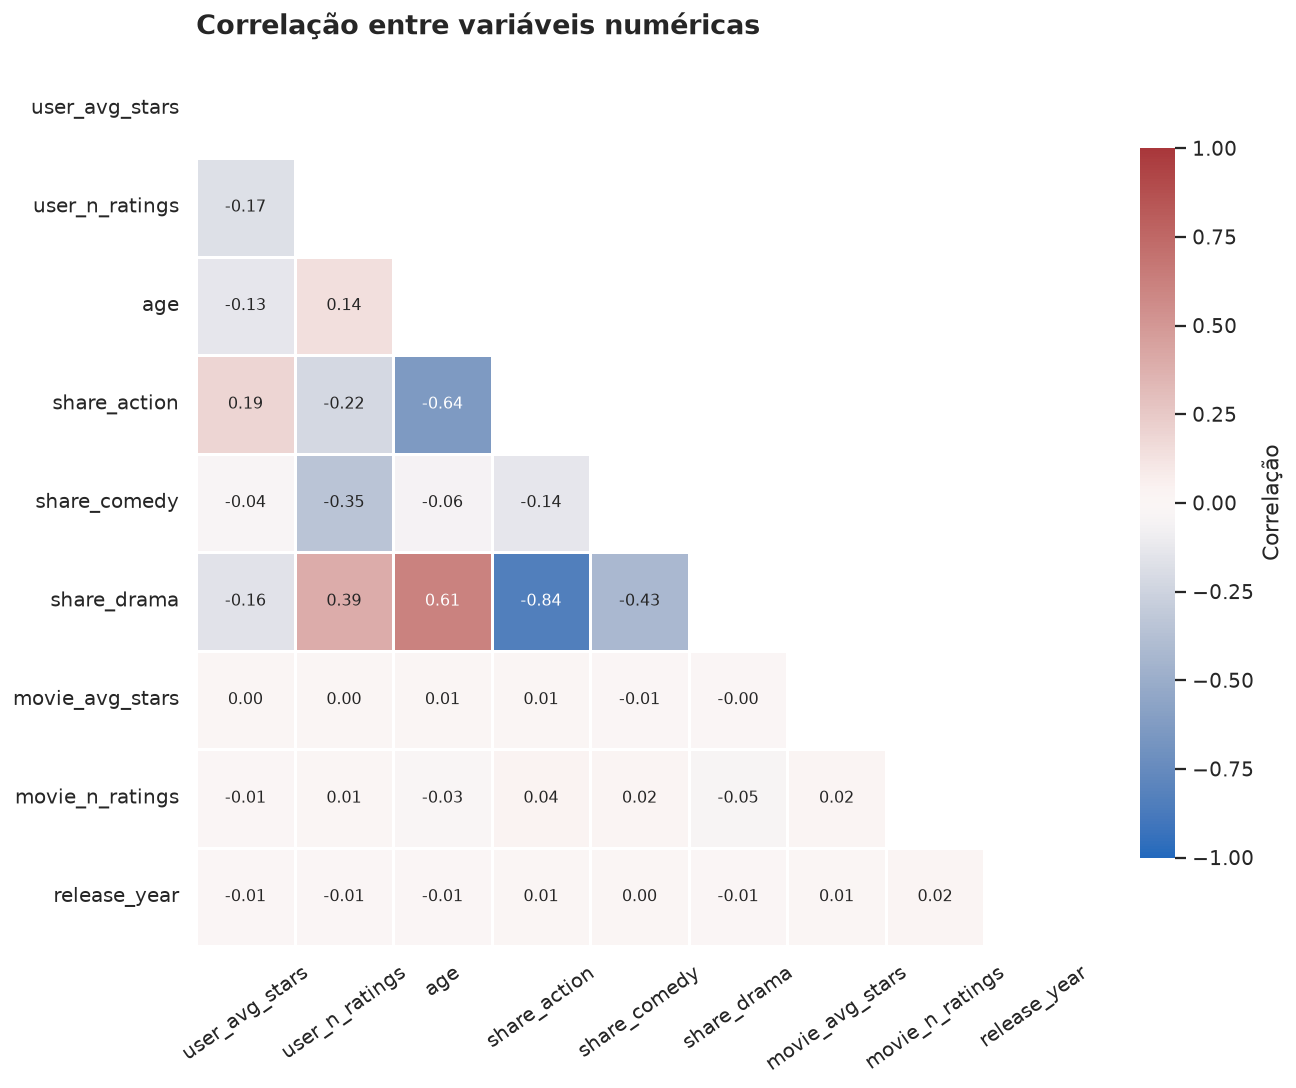

In [59]:
df_num = df.select_dtypes(include="number")
matriz_corr = df_num.corr()
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.8,
    linecolor="white",
    square=True,
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8, "label": "Correlação"},
    ax=ax,
)
ax.set_title("Correlação entre variáveis numéricas", loc="left", fontsize=15, pad=14)
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()


### Análise de Multicolinearidade

In [62]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif1 = df_num.copy()
vif_df = pd.DataFrame({
    "Variável": X_vif1.columns[1:],
    "VIF": [
        variance_inflation_factor(X_vif1.to_numpy(), i)
        for i in range(1, X_vif1.shape[1])
    ],
})
vif_df.sort_values("VIF", ascending=False)


,Variável,VIF
4,share_drama,172335.465699
2,share_action,143738.780527
3,share_comedy,52936.019430
1,age,1.758481
0,user_n_ratings,1.280027
6,movie_n_ratings,1.004460
5,movie_avg_stars,1.001688
7,release_year,1.001228


**Comentários**

In [65]:
X_vif2 = add_constant(df_num.drop(columns=["share_comedy"], errors="ignore"))
vif_df = pd.DataFrame({
    "Variável": X_vif2.columns[1:],
    "VIF": [
        variance_inflation_factor(X_vif2.to_numpy(), i)
        for i in range(1, X_vif2.shape[1])
    ],
})
vif_df.sort_values("VIF", ascending=False)


,Variável,VIF
4,share_drama,4.124366
3,share_action,3.805929
2,age,1.757760
1,user_n_ratings,1.279985
0,user_avg_stars,1.065324
6,movie_n_ratings,1.003757
5,movie_avg_stars,1.001027
7,release_year,1.000655


**Comentários**

### Regressão Linear

In [66]:
import statsmodels.formula.api as smf

dados = df.copy()
dados["stars"] = pd.to_numeric(dados["stars"], errors="coerce")
dados = dados.dropna(subset=["stars"]).copy()
dados["log_user_n_ratings"] = np.log1p(dados["user_n_ratings"])

formula = """stars ~ user_avg_stars + log_user_n_ratings + age
             + share_action + share_drama
             + movie_avg_stars + np.log1p(movie_n_ratings)
             + C(genre) + release_year"""

modelo = smf.ols(formula, data=dados).fit()
print(modelo.summary())


                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     397.6
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:34:20   Log-Likelihood:                -4905.1
No. Observations:                4000   AIC:                             9832.
Df Residuals:                    3989   BIC:                             9902.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

**Comentários**

In [67]:
# Criando variável de afinidade do usuário com o gênero do filme

dados["afinidade"] = np.select(
    [dados["genre"].eq("action"), dados["genre"].eq("comedy")],
    [dados["share_action"], dados["share_comedy"]],
    default=dados["share_drama"],
)

formula2 = """stars ~ user_avg_stars + log_user_n_ratings + age
             + movie_avg_stars + C(genre) + release_year"""

modelo2 = smf.ols(formula2 + " + afinidade", data=dados).fit()
print(modelo2.summary())


                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.671
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     1020.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:34:50   Log-Likelihood:                -4061.8
No. Observations:                4000   AIC:                             8142.
Df Residuals:                    3991   BIC:                             8198.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -8.2700      1

**Comentários**

##### Comparação do RMSE

In [69]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

def rmse_cv(formula, dados, k=8):
    dados_cv = dados.dropna(subset=["stars"]).copy()
    erros, erros_base = [], []
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    for tr, va in cv.split(dados_cv):
        treino, valid = dados_cv.iloc[tr], dados_cv.iloc[va]
        pred = smf.ols(formula, data=treino).fit().predict(valid)
        pred = np.clip(np.asarray(pred), 0, 5)
        y_valid = valid["stars"].to_numpy(dtype=float)
        erros.append(mean_squared_error(y_valid, pred) ** 0.5)
        erros_base.append(
            mean_squared_error(
                y_valid, np.full(len(valid), treino["stars"].mean())
            ) ** 0.5
        )
    return np.mean(erros), np.mean(erros_base)

print("OLS Multicolinear:", rmse_cv(formula, dados))
print("OLS Não-Multicolinear:", rmse_cv(formula2 + " + afinidade", dados))


OLS Multicolinear: (np.float64(0.8220425365917434), np.float64(1.164595457736997))
OLS Não-Multicolinear: (np.float64(0.6542286460122859), np.float64(1.164595457736997))


**Comentários**

### Regressão Logística Ordinal

In [70]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

valores_estrelas = sorted(dados["stars"].unique())
recursos = [
    "user_avg_stars",
    "log_user_n_ratings",
    "age",
    "movie_avg_stars",
    "release_year",
    "afinidade",
    "genre",
]
X = pd.get_dummies(dados[recursos], drop_first=True, dtype=float)
y_ordinal = pd.Categorical(
    dados["stars"], categories=valores_estrelas, ordered=True
)
modelo_ordinal = OrderedModel(y_ordinal, X, distr="logit")
resultado_ordinal = modelo_ordinal.fit(method="bfgs", disp=False)
print(resultado_ordinal.summary())


                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -3755.1
Model:                   OrderedModel   AIC:                             7536.
Method:            Maximum Likelihood   BIC:                             7618.
Date:                Mon, 02 Nov 2026                                         
Time:                        12:35:48                                         
No. Observations:                4000                                         
Df Residuals:                    3987                                         
Df Model:                           8                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
user_avg_stars         2.2312      0.060     37.448      0.000       2.114       2.348
log_user_n_ratings    -0.152

**Comentários**

##### Cálculo do RMSE

In [72]:
def ordinal_rmse_cv(dados, recursos, k=8):
    dados_cv = dados.dropna(subset=["stars"]).copy()
    classes = sorted(dados_cv["stars"].unique())
    erros = []
    cv = KFold(n_splits=k, shuffle=True, random_state=42)
    for tr, va in cv.split(dados_cv):
        treino, valid = dados_cv.iloc[tr], dados_cv.iloc[va]
        X_treino = pd.get_dummies(treino[recursos], drop_first=True, dtype=float)
        X_valid = pd.get_dummies(valid[recursos], drop_first=True, dtype=float)
        X_valid = X_valid.reindex(columns=X_treino.columns, fill_value=0)
        y_treino = pd.Categorical(
            treino["stars"], categories=classes, ordered=True
        )
        ajuste = OrderedModel(y_treino, X_treino, distr="logit").fit(
            method="bfgs", disp=False
        )
        probabilidades = ajuste.predict(X_valid)
        pred = np.asarray(probabilidades) @ np.asarray(classes)
        erros.append(
            mean_squared_error(valid["stars"].to_numpy(dtype=float), pred) ** 0.5
        )
    return np.mean(erros)

rmse_ordinal_cv = ordinal_rmse_cv(dados, recursos)
print(f"RMSE médio da regressão ordinal (validação cruzada): {rmse_ordinal_cv:.5f}")


/home/marcos_junior/Faculdade/6semestre/MAE0501 - AE/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1189: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = fit_method(


RMSE médio da regressão ordinal (validação cruzada): 0.64490


### Random Forest

In [73]:
from sklearn.ensemble import RandomForestRegressor

dados_modelo = dados.dropna(subset=["stars"]).copy()
kf = KFold(n_splits=8, shuffle=True, random_state=42)
erros_rf = []

for tr, va in kf.split(dados_modelo):
    treino, valid = dados_modelo.iloc[tr], dados_modelo.iloc[va]
    X_treino = pd.get_dummies(treino[recursos], drop_first=True, dtype=float)
    X_valid = pd.get_dummies(valid[recursos], drop_first=True, dtype=float)
    X_valid = X_valid.reindex(columns=X_treino.columns, fill_value=0)
    y_treino = treino["stars"].astype(float)
    y_valid = valid["stars"].astype(float)
    modelo_rf = RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )
    modelo_rf.fit(X_treino, y_treino)
    pred = np.clip(modelo_rf.predict(X_valid), 0, 5)
    erros_rf.append(mean_squared_error(y_valid, pred) ** 0.5)

rmse_rf_cv = float(np.mean(erros_rf))
print(f"RMSE médio do Random Forest (validação cruzada): {rmse_rf_cv:.5f}")


RMSE médio do Random Forest (validação cruzada): 0.59763


### Comparação dos Modelos

In [75]:
comparacao = pd.DataFrame(
    {
        "RMSE médio": [
            rmse_cv(formula, dados)[0],
            rmse_cv(formula2 + " + afinidade", dados)[0],
            rmse_ordinal_cv,
            rmse_rf_cv,
        ]
    },
    index=[
        "Regressão linear com multicolinearidade",
        "Regressão linear com não-multicolinearidade",
        "Regressão ordinal",
        "Random Forest",
    ],
).sort_values("RMSE médio")
comparacao


,RMSE médio
Random Forest,0.597634
Regressão ordinal,0.644900
Regressão linear com não-multicolinearidade,0.654229
Regressão linear com multicolinearidade,0.822043
